Player data:
   season   lg            player  player_id   age team pos   g    gs  \
0    2026  NBA  Precious Achiuwa  achiupr01  26.0  SAC   C  73  57.0   
1    2026  NBA      Steven Adams  adamsst01  32.0  HOU   C  32  11.0   
2    2026  NBA       Bam Adebayo  adebaba01  28.0  MIA   C  73  73.0   
3    2026  NBA      Ochai Agbaji  agbajoc01  25.0  2TM  SG  62  13.0   
4    2026  NBA      Ochai Agbaji  agbajoc01  25.0  TOR  SG  42  13.0   

   mp_per_game  ...  ft_percent  orb_per_game  drb_per_game  trb_per_game  \
0         23.9  ...       0.554           2.4           4.3           6.7   
1         22.8  ...       0.580           4.5           4.1           8.6   
2         32.4  ...       0.778           2.0           8.0          10.0   
3         15.7  ...       0.837           0.7           1.5           2.3   
4         15.5  ...       0.862           0.8           1.5           2.3   

   ast_per_game  stl_per_game  blk_per_game  tov_per_game  pf_per_game  \
0           1.4  

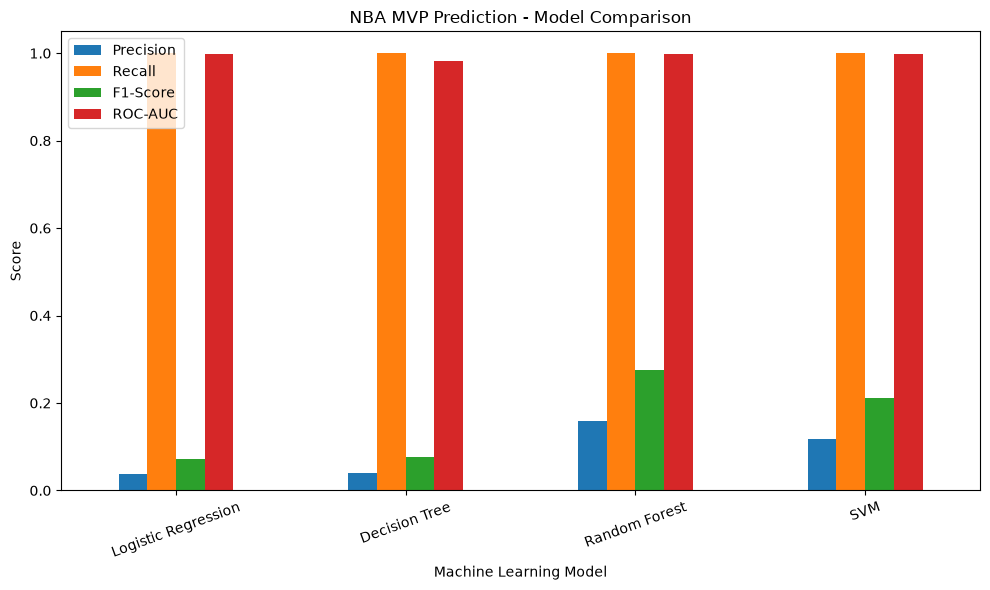

Random Forest Feature Importance:
     Feature  Importance
pts_per_game    0.276165
tov_per_game    0.171802
 mp_per_game    0.138713
ast_per_game    0.113675
          gs    0.108230
trb_per_game    0.064802
  fg_percent    0.032633
stl_per_game    0.027132
           g    0.018326
  ft_percent    0.014865
blk_per_game    0.014585
         age    0.010176
 x3p_percent    0.008896


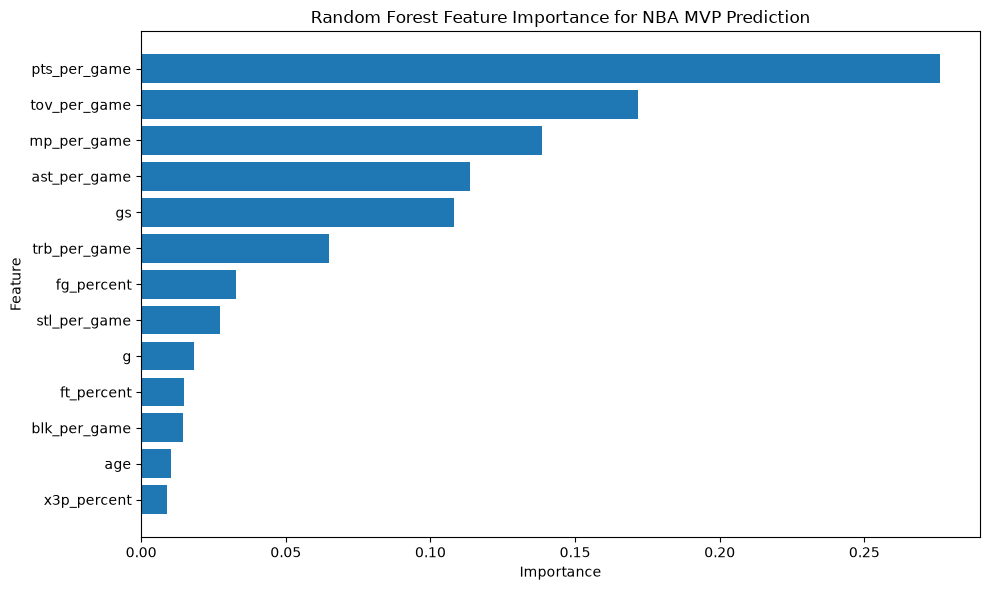

Predictions generated successfully.

Available columns:
['age', 'g', 'gs', 'mp_per_game', 'fg_percent', 'x3p_percent', 'ft_percent', 'trb_per_game', 'ast_per_game', 'stl_per_game', 'blk_per_game', 'tov_per_game', 'pts_per_game', 'MVP', 'Logistic_Probability', 'DecisionTree_Probability', 'RandomForest_Probability', 'SVM_Probability']

First 10 predictions:
     age   g    gs  mp_per_game  fg_percent  x3p_percent  ft_percent  \
0   26.0  73  57.0         23.9       0.528        0.278       0.554   
2   28.0  73  73.0         32.4       0.442        0.318       0.778   
3   25.0  62  13.0         15.7       0.436        0.266       0.837   
4   25.0  43  11.0         27.9       0.479        0.350       0.667   
5   27.0  78  71.0         33.4       0.459        0.399       0.902   
6   22.0   9   0.0         12.3       0.514        0.500       0.600   
7   30.0  51  27.0         28.8       0.403        0.349       0.857   
8   27.0  56  56.0         27.1       0.638        0.100       0.7

In [44]:
import pandas as pd

players = pd.read_csv("../data/Player Per Game.csv")
awards = pd.read_csv("../data/Player Award Shares.csv")

print("Player data:")
print(players.head())

print("\nAward data:")
print(awards.head())
print("PLAYER DATA SHAPE:")
print(players.shape)

print("\nPLAYER DATA COLUMNS:")
print(players.columns.tolist())

print("\nAWARD DATA SHAPE:")
print(awards.shape)

print("\nAWARD DATA COLUMNS:")
print(awards.columns.tolist())

print(awards["award"].value_counts())
mvp_awards = awards[awards["award"] == "nba mvp"]

print("Number of MVP records:", len(mvp_awards))
print("\nMVP records:")
print(mvp_awards.head(10))
print(awards["award"].unique())
mvp_awards = awards[awards["award"] == "nba mvp"].copy()

print("Number of MVP records:", len(mvp_awards))

print("\nMVP records:")
print(mvp_awards[[
    "season",
    "player",
    "player_id",
    "pts_won",
    "pts_max",
    "share",
    "winner"
]].head(20).to_string(index=False))
print("Total MVP voting records:", len(mvp_awards))

print("\nMVP winners:")
print(
    mvp_awards[mvp_awards["winner"] == True][
        ["season", "player", "share"]
    ].to_string(index=False)
)
duplicates = players.duplicated(
    subset=["season", "player_id"],
    keep=False
)

print("Number of rows belonging to duplicate player-seasons:",
      duplicates.sum())

print("\nExamples:")
print(
    players.loc[duplicates, ["season", "player", "player_id", "team"]]
    .head(20)
    .to_string(index=False)
)
# Keep the combined "2TM" row for players who played for multiple teams.
# For players who stayed with one team, keep their regular team row.

players_clean = players[
    (players["team"] == "2TM") |
    (~players.duplicated(subset=["season", "player_id"], keep=False))
].copy()

print("Original rows:", len(players))
print("Clean rows:", len(players_clean))

print("\nDuplicate player-seasons after cleaning:")
print(
    players_clean.duplicated(
        subset=["season", "player_id"]
    ).sum()
)
# Keep only players who actually won MVP
mvp_winners = mvp_awards[
    mvp_awards["winner"] == True
][
    ["season", "player_id", "player"]
].copy()

# Create target variable
mvp_winners["MVP"] = 1

print("Number of MVP winners:", len(mvp_winners))
print("\nMVP winners:")
print(mvp_winners.to_string(index=False))
# Merge player statistics with MVP winners
dataset = players_clean.merge(
    mvp_winners[["season", "player_id", "MVP"]],
    on=["season", "player_id"],
    how="left"
)

# Players who are not MVP winners get MVP = 0
dataset["MVP"] = dataset["MVP"].fillna(0).astype(int)

print("Dataset shape:", dataset.shape)

print("\nMVP distribution:")
print(dataset["MVP"].value_counts())

print("\nSample data:")
print(
    dataset[
        ["season", "player", "player_id", "pts_per_game",
         "trb_per_game", "ast_per_game", "MVP"]
    ].head(10)
)
print("Total records:", len(dataset))
print("MVP = 1:", (dataset["MVP"] == 1).sum())
print("MVP = 0:", (dataset["MVP"] == 0).sum())

print("\nMVP winners in merged dataset:")
print(
    dataset[dataset["MVP"] == 1][
        ["season", "player", "pts_per_game", "trb_per_game",
         "ast_per_game", "MVP"]
    ].to_string(index=False)
)
features = [
    "age",
    "g",
    "gs",
    "mp_per_game",
    "fg_percent",
    "x3p_percent",
    "ft_percent",
    "trb_per_game",
    "ast_per_game",
    "stl_per_game",
    "blk_per_game",
    "tov_per_game",
    "pts_per_game"
]

target = "MVP"

model_data = dataset[features + [target]].copy()

print("Model dataset shape:", model_data.shape)
print("\nSelected features:")
print(features)
print("Missing values:")
print(model_data.isnull().sum())
model_data = model_data.dropna()

print("Dataset shape after cleaning:", model_data.shape)

print("\nTotal missing values:")
print(model_data.isnull().sum().sum())
print("MVP target distribution:")
print(model_data["MVP"].value_counts())

print("\nMVP percentage:")
print(model_data["MVP"].value_counts(normalize=True) * 100)
model_data.to_csv(
    "../outputs/nba_mvp_model_data.csv",
    index=False
)

print("Cleaned dataset saved successfully.")
X = model_data[features]
y = model_data["MVP"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFirst 5 rows of X:")
print(X.head())

print("\nFirst 5 values of y:")
print(y.head())
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining MVP distribution:")
print(y_train.value_counts())

print("\nTesting MVP distribution:")
print(y_test.value_counts())
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)
# Time-based train/test split

train_data = model_data[dataset.loc[model_data.index, "season"] <= 2021].copy()
test_data = model_data[dataset.loc[model_data.index, "season"] >= 2022].copy()

X_train = train_data[features]
y_train = train_data["MVP"]

X_test = test_data[features]
y_test = test_data["MVP"]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining seasons:")
print(train_data.shape[0], "records")

print("\nTesting seasons:")
print(test_data.shape[0], "records")

print("\nTraining MVP distribution:")
print(y_train.value_counts())

print("\nTesting MVP distribution:")
print(y_test.value_counts())
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)
print("TRAINING SET")
print("Records:", len(X_train))
print("MVP winners:", y_train.sum())
print("Non-MVP:", (y_train == 0).sum())

print("\nTESTING SET")
print("Records:", len(X_test))
print("MVP winners:", y_test.sum())
print("Non-MVP:", (y_test == 0).sum())

print("\nTraining MVP percentage:",
      y_train.mean() * 100, "%")

print("Testing MVP percentage:",
      y_test.mean() * 100, "%")

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

y_pred_lr = logistic_model.predict(X_test_scaled)
y_prob_lr = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("===== LOGISTIC REGRESSION =====")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=5,
    random_state=42
)

decision_tree_model.fit(X_train_scaled, y_train)

y_pred_dt = decision_tree_model.predict(X_test_scaled)
y_prob_dt = decision_tree_model.predict_proba(X_test_scaled)[:, 1]

print("===== DECISION TREE =====")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    max_depth=8,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_scaled, y_train)

y_pred_rf = random_forest_model.predict(X_test_scaled)
y_prob_rf = random_forest_model.predict_proba(X_test_scaled)[:, 1]

print("===== RANDOM FOREST =====")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
from sklearn.svm import SVC

svm_model = SVC(
    class_weight="balanced",
    probability=True,
    kernel="rbf",
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

print("===== SUPPORT VECTOR MACHINE =====")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

results = []

models = {
    "Logistic Regression": (y_test, y_pred_lr, y_prob_lr),
    "Decision Tree": (y_test, y_pred_dt, y_prob_dt),
    "Random Forest": (y_test, y_pred_rf, y_prob_rf),
    "SVM": (y_test, y_pred_svm, y_prob_svm)
}

for name, (actual, predicted, probability) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1-Score": f1_score(actual, predicted, zero_division=0),
        "ROC-AUC": roc_auc_score(actual, probability)
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))
import matplotlib.pyplot as plt

results_plot = results_df.set_index("Model")[
    ["Precision", "Recall", "F1-Score", "ROC-AUC"]
]

results_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("NBA MVP Prediction - Model Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print("Random Forest Feature Importance:")
print(feature_importance.to_string(index=False))
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance for NBA MVP Prediction")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
# Step 31: Generate MVP probabilities using all 4 models

prediction_data = test_data.copy()

# Scale the test features
X_prediction_scaled = scaler.transform(
    prediction_data[features]
)

# Generate probabilities from all 4 models

prediction_data["Logistic_Probability"] = (
    logistic_model.predict_proba(X_prediction_scaled)[:, 1]
)

prediction_data["DecisionTree_Probability"] = (
    decision_tree_model.predict_proba(X_prediction_scaled)[:, 1]
)

prediction_data["RandomForest_Probability"] = (
    random_forest_model.predict_proba(X_prediction_scaled)[:, 1]
)

prediction_data["SVM_Probability"] = (
    svm_model.predict_proba(X_prediction_scaled)[:, 1]
)

print("Predictions generated successfully.")

# Show available columns
print("\nAvailable columns:")
print(prediction_data.columns.tolist())

# Show first 10 predictions
print("\nFirst 10 predictions:")
print(prediction_data.head(10))
# Step 32: Check the original player information

print("Original players columns:")
print(players.columns.tolist())

print("\nPrediction data index:")
print(prediction_data.index[:10].tolist())
# Step 33: Add player names and seasons to prediction results

prediction_data["player"] = players.loc[
    prediction_data.index, "player"
]

prediction_data["season"] = players.loc[
    prediction_data.index, "season"
]

# Arrange important columns first
prediction_results = prediction_data[
    [
        "season",
        "player",
        "Logistic_Probability",
        "DecisionTree_Probability",
        "RandomForest_Probability",
        "SVM_Probability"
    ]
].copy()

print("Player names successfully added.")

print(
    prediction_results.head(20).to_string(index=False)
)
# STEP 34 - Top 10 MVP Candidates from All 4 Models

print("========== TOP 10 MVP CANDIDATES ==========")

print("\n--- Logistic Regression ---")
print(
    prediction_data
    .sort_values("Logistic_Probability", ascending=False)
    [["season", "player", "Logistic_Probability"]]
    .head(10)
    .to_string(index=False)
)

print("\n--- Decision Tree ---")
print(
    prediction_data
    .sort_values("DecisionTree_Probability", ascending=False)
    [["season", "player", "DecisionTree_Probability"]]
    .head(10)
    .to_string(index=False)
)

print("\n--- Random Forest ---")
print(
    prediction_data
    .sort_values("RandomForest_Probability", ascending=False)
    [["season", "player", "RandomForest_Probability"]]
    .head(10)
    .to_string(index=False)
)

print("\n--- SVM ---")
print(
    prediction_data
    .sort_values("SVM_Probability", ascending=False)
    [["season", "player", "SVM_Probability"]]
    .head(10)
    .to_string(index=False)
)

In [46]:
# STEP 34 - Top 10 MVP Candidates

print("========== TOP 10 MVP CANDIDATES ==========")

for model in [
    "Logistic_Probability",
    "DecisionTree_Probability",
    "RandomForest_Probability",
    "SVM_Probability"
]:
    print("\n---", model, "---")
    
    temp = prediction_data.sort_values(
        model,
        ascending=False
    )[["season", "player", model]].head(10)
    
    print(temp.to_string(index=False))
    # STEP 35 - Combined MVP Score from All 4 Models

prediction_data["Combined_MVP_Score"] = (
    prediction_data["Logistic_Probability"] +
    prediction_data["DecisionTree_Probability"] +
    prediction_data["RandomForest_Probability"] +
    prediction_data["SVM_Probability"]
) / 4

final_mvp_ranking = prediction_data.sort_values(
    "Combined_MVP_Score",
    ascending=False
)[
    [
        "season",
        "player",
        "Logistic_Probability",
        "DecisionTree_Probability",
        "RandomForest_Probability",
        "SVM_Probability",
        "Combined_MVP_Score"
    ]
]

print("========== FINAL MVP RANKING ==========")
print(final_mvp_ranking.head(20).to_string(index=False))

========== TOP 10 MVP CANDIDATES ==========

--- Logistic_Probability ---
 season                   player  Logistic_Probability
   2026           Jordan Hawkins              0.999999
   2025 Kentavious Caldwell-Pope              0.999997
   2025                Paul Reed              0.999994
   2025            Norman Powell              0.999993
   2025             Jaylon Tyson              0.999962
   2024            Jontay Porter              0.999957
   2023              Bryn Forbes              0.999952
   2024         Dereck Lively II              0.999944
   2023            Herbert Jones              0.999913
   2026          Donovan Clingan              0.999890

--- DecisionTree_Probability ---
 season              player  DecisionTree_Probability
   2025      T.J. McConnell                  0.973675
   2025       Mason Plumlee                  0.973675
   2026          Coby White                  0.973675
   2025        Terry Rozier                  0.973675
   2025       Jal

In [48]:
# STEP 34 - Top 5 Candidates from Each Model

models = {
    "Logistic Regression": "Logistic_Probability",
    "Decision Tree": "DecisionTree_Probability",
    "Random Forest": "RandomForest_Probability",
    "SVM": "SVM_Probability"
}

for model_name, column in models.items():
    print("\n" + "=" * 50)
    print(model_name)
    print("=" * 50)

    top5 = prediction_data.nlargest(
        5, column
    )[["season", "player", column]]

    print(top5.to_string(index=False))
    # STEP 34B - SVM Top 5 Candidates

print("========== SVM TOP 5 CANDIDATES ==========")

svm_top5 = prediction_data.nlargest(
    5,
    "SVM_Probability"
)[
    ["season", "player", "SVM_Probability"]
]

print(svm_top5.to_string(index=False))


Logistic Regression
 season                   player  Logistic_Probability
   2026           Jordan Hawkins              0.999999
   2025 Kentavious Caldwell-Pope              0.999997
   2025                Paul Reed              0.999994
   2025            Norman Powell              0.999993
   2025             Jaylon Tyson              0.999962

Decision Tree
 season           player  DecisionTree_Probability
   2026    Kyle Anderson                  0.973675
   2026  Dominick Barlow                  0.973675
   2026 MarJon Beauchamp                  0.973675
   2026  Colin Castleton                  0.973675
   2026  Donovan Clingan                  0.973675

Random Forest
 season          player  RandomForest_Probability
   2025    Jaylon Tyson                  0.780722
   2025 Lester Quiñones                  0.777920
   2026    John Collins                  0.747601
   2023   Herbert Jones                  0.685313
   2025      Drew Timme                  0.680316

SVM
 season 

In [49]:
# CHECK SVM COLUMN

print("Columns containing SVM:")

for col in prediction_data.columns:
    if "SVM" in col.upper():
        print(col)

print("\nSVM prediction column:")
print(prediction_data["SVM_Probability"].head(10))

Columns containing SVM:
SVM_Probability

SVM prediction column:
0     0.000062
2     0.000296
3     0.001016
4     0.000048
5     0.000304
6     0.001899
7     0.000020
8     0.000116
9     0.000163
10    0.002472
Name: SVM_Probability, dtype: float64


In [55]:
# STEP 34B - SVM Top 5

print("========== SVM TOP 5 CANDIDATES ==========")

svm_top5 = prediction_data.nlargest(
    5,
    "SVM_Probability"
)[["season", "player", "SVM_Probability"]]

print(svm_top5.to_string(index=False))
# STEP 35 - Final Ensemble MVP Ranking

prediction_data["LR_Rank"] = prediction_data["Logistic_Probability"].rank(
    ascending=False, method="min"
)

prediction_data["DT_Rank"] = prediction_data["DecisionTree_Probability"].rank(
    ascending=False, method="min"
)

prediction_data["RF_Rank"] = prediction_data["RandomForest_Probability"].rank(
    ascending=False, method="min"
)

prediction_data["SVM_Rank"] = prediction_data["SVM_Probability"].rank(
    ascending=False, method="min"
)

prediction_data["Average_Rank"] = (
    prediction_data["LR_Rank"]
    + prediction_data["DT_Rank"]
    + prediction_data["RF_Rank"]
    + prediction_data["SVM_Rank"]
) / 4

final_ranking = prediction_data.sort_values(
    "Average_Rank"
)

print("========== FINAL ENSEMBLE MVP RANKING ==========")

print(
    final_ranking[
        [
            "season",
            "player",
            "Logistic_Probability",
            "DecisionTree_Probability",
            "RandomForest_Probability",
            "SVM_Probability",
            "Average_Rank"
        ]
    ].head(20).to_string(index=False)
)
# STEP 36 - Final Top 10 MVP Predictions

top_10_final = final_ranking[
    [
        "season",
        "player",
        "Logistic_Probability",
        "DecisionTree_Probability",
        "RandomForest_Probability",
        "SVM_Probability",
        "Average_Rank"
    ]
].head(10)

print("========== TOP 10 PREDICTED MVP CANDIDATES ==========")
print(top_10_final.to_string(index=False))
# STEP 37 - Final Top 10 MVP Candidates

final_top10 = final_ranking.head(10).copy()

print("========== FINAL TOP 10 MVP CANDIDATES ==========")
print(
    final_top10[
        [
            "season",
            "player",
            "Logistic_Probability",
            "DecisionTree_Probability",
            "RandomForest_Probability",
            "SVM_Probability",
            "Average_Rank"
        ]
    ].to_string(index=False)
)

========== SVM TOP 5 CANDIDATES ==========
 season                   player  SVM_Probability
   2025             Jaylon Tyson         0.826470
   2023            Herbert Jones         0.744573
   2025 Kentavious Caldwell-Pope         0.740605
   2025             Cole Anthony         0.668193
   2026           Jordan Hawkins         0.633510
========== FINAL ENSEMBLE MVP RANKING ==========
 season                   player  Logistic_Probability  DecisionTree_Probability  RandomForest_Probability  SVM_Probability  Average_Rank
   2025             Jaylon Tyson              0.999962                  0.973675                  0.780722         0.826470          2.00
   2025 Kentavious Caldwell-Pope              0.999997                  0.973675                  0.647017         0.740605          3.25
   2026           Jordan Hawkins              0.999999                  0.973675                  0.651749         0.633510          3.25
   2023            Herbert Jones              0.999913  

In [56]:
# STEP 37 - FINAL TOP 10 MVP CANDIDATES

final_top10 = final_ranking.head(10)

print("\n========== FINAL TOP 10 MVP CANDIDATES ==========\n")

print(
    final_top10[
        [
            "season",
            "player",
            "Logistic_Probability",
            "DecisionTree_Probability",
            "RandomForest_Probability",
            "SVM_Probability",
            "Average_Rank"
        ]
    ].to_string(index=False)
)


========== FINAL TOP 10 MVP CANDIDATES ==========

 season                   player  Logistic_Probability  DecisionTree_Probability  RandomForest_Probability  SVM_Probability  Average_Rank
   2025             Jaylon Tyson              0.999962                  0.973675                  0.780722         0.826470          2.00
   2025 Kentavious Caldwell-Pope              0.999997                  0.973675                  0.647017         0.740605          3.25
   2026           Jordan Hawkins              0.999999                  0.973675                  0.651749         0.633510          3.25
   2023            Herbert Jones              0.999913                  0.973675                  0.685313         0.744573          4.00
   2025            Norman Powell              0.999993                  0.973675                  0.557270         0.593132          7.75
   2025             Cole Anthony              0.999750                  0.973675                  0.583901         0.668

In [57]:
# STEP 38 - PREDICTED MVP

mvp_winner = final_ranking.iloc[0]

print("\n========== PREDICTED MVP ==========\n")

print("Season :", int(mvp_winner["season"]))
print("Player :", mvp_winner["player"])
print("Average Rank :", mvp_winner["Average_Rank"])

print("\nModel Probabilities:")
print("Logistic Regression :", mvp_winner["Logistic_Probability"])
print("Decision Tree       :", mvp_winner["DecisionTree_Probability"])
print("Random Forest       :", mvp_winner["RandomForest_Probability"])
print("SVM                 :", mvp_winner["SVM_Probability"])


========== PREDICTED MVP ==========

Season : 2025
Player : Jaylon Tyson
Average Rank : 2.0

Model Probabilities:
Logistic Regression : 0.9999617571689445
Decision Tree       : 0.9736745880257663
Random Forest       : 0.7807220241796776
SVM                 : 0.8264704429776326


In [58]:
import os

# STEP 39 - SAVE FINAL MVP RANKING

os.makedirs("../outputs", exist_ok=True)
final_ranking.to_csv("../outputs/final_mvp_ranking.csv", index=False)

print("Final MVP ranking saved successfully.")
print("File: final_mvp_ranking.csv")

Final MVP ranking saved successfully.
File: final_mvp_ranking.csv


In [59]:
# STEP 40 - FINAL MODEL SUMMARY

print("\n========== NBA MVP PREDICTION SUMMARY ==========\n")

print("Number of models used: 4")

print("\nModels:")
print("1. Logistic Regression")
print("2. Decision Tree")
print("3. Random Forest")
print("4. Support Vector Machine (SVM)")

print("\nPredicted MVP:")
print(mvp_winner["player"])

print("Season:")
print(int(mvp_winner["season"]))

print("Average Rank:")
print(mvp_winner["Average_Rank"])

print("\nTop 5 MVP Candidates:")
print(
    final_ranking[
        ["season", "player", "Average_Rank"]
    ].head(5).to_string(index=False)
)


========== NBA MVP PREDICTION SUMMARY ==========

Number of models used: 4

Models:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine (SVM)

Predicted MVP:
Jaylon Tyson
Season:
2025
Average Rank:
2.0

Top 5 MVP Candidates:
 season                   player  Average_Rank
   2025             Jaylon Tyson          2.00
   2025 Kentavious Caldwell-Pope          3.25
   2026           Jordan Hawkins          3.25
   2023            Herbert Jones          4.00
   2025            Norman Powell          7.75


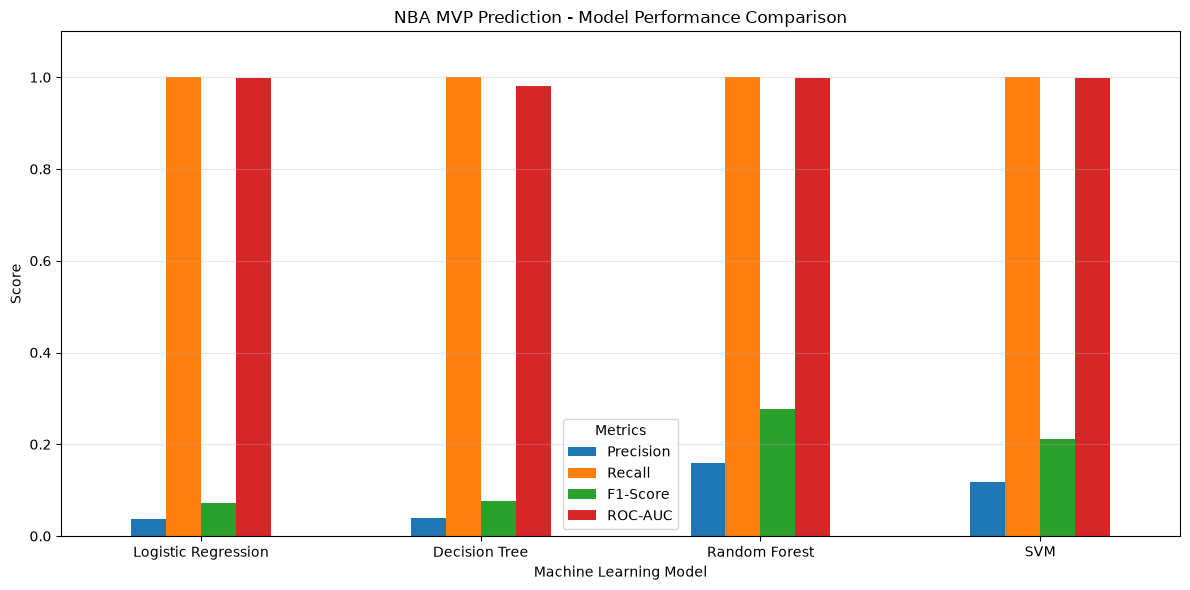

In [60]:
# STEP 41 - MODEL PERFORMANCE COMPARISON

import matplotlib.pyplot as plt

# Select the important evaluation metrics
metrics = ["Precision", "Recall", "F1-Score", "ROC-AUC"]

# Create comparison dataframe
model_comparison = results_df.set_index("Model")[metrics]

# Plot
ax = model_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("NBA MVP Prediction - Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


========== RANDOM FOREST FEATURE IMPORTANCE ==========

     Feature  Importance
pts_per_game    0.276165
tov_per_game    0.171802
 mp_per_game    0.138713
ast_per_game    0.113675
          gs    0.108230
trb_per_game    0.064802
  fg_percent    0.032633
stl_per_game    0.027132
           g    0.018326
  ft_percent    0.014865
blk_per_game    0.014585
         age    0.010176
 x3p_percent    0.008896

========== DECISION TREE FEATURE IMPORTANCE ==========

     Feature  Importance
pts_per_game    0.884768
ast_per_game    0.091399
trb_per_game    0.006340
 x3p_percent    0.005926
tov_per_game    0.004157
         age    0.004058
          gs    0.003351
           g    0.000000
 mp_per_game    0.000000
  fg_percent    0.000000
  ft_percent    0.000000
blk_per_game    0.000000
stl_per_game    0.000000

========== LOGISTIC REGRESSION FEATURE IMPORTANCE ==========

     Feature  Importance
pts_per_game    4.192139
  ft_percent    2.693219
ast_per_game    2.084282
          gs    1.70923

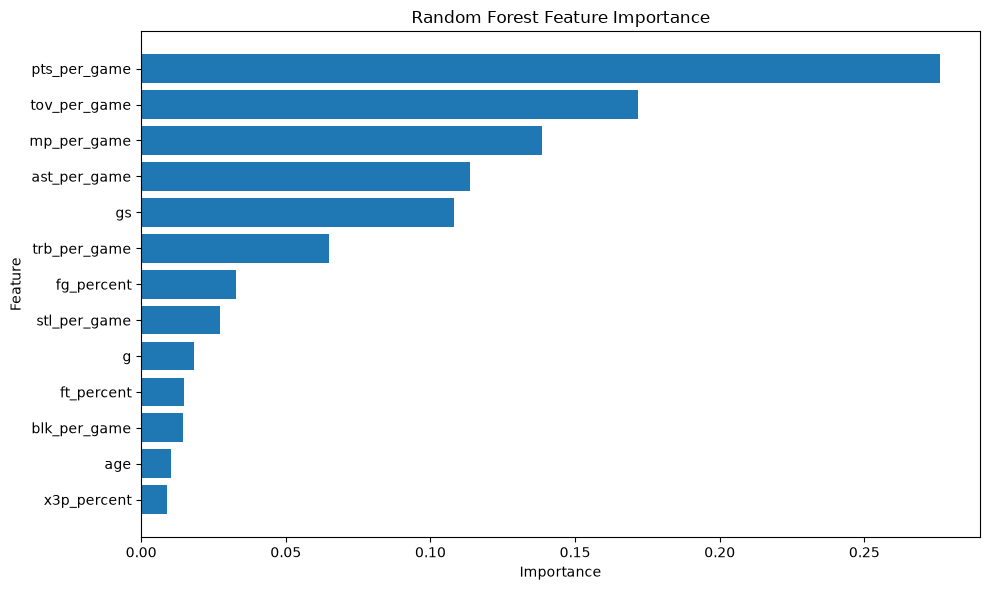

In [63]:
# STEP 42 - FEATURE IMPORTANCE / MODEL INTERPRETATION

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.inspection import permutation_importance

# Feature names
feature_names = X_train.columns


# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

rf_importance = random_forest_model.feature_importances_

rf_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importance
}).sort_values("Importance", ascending=False)

print("\n========== RANDOM FOREST FEATURE IMPORTANCE ==========\n")
print(rf_df.to_string(index=False))


# ============================================================
# DECISION TREE FEATURE IMPORTANCE
# ============================================================

dt_importance = decision_tree_model.feature_importances_

dt_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": dt_importance
}).sort_values("Importance", ascending=False)

print("\n========== DECISION TREE FEATURE IMPORTANCE ==========\n")
print(dt_df.to_string(index=False))


# ============================================================
# LOGISTIC REGRESSION FEATURE IMPORTANCE
# ============================================================

lr_importance = np.abs(logistic_model.coef_[0])

lr_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": lr_importance
}).sort_values("Importance", ascending=False)

print("\n========== LOGISTIC REGRESSION FEATURE IMPORTANCE ==========\n")
print(lr_df.to_string(index=False))


# ============================================================
# SVM FEATURE IMPORTANCE
# USING PERMUTATION IMPORTANCE
# ============================================================

# ============================================================
# SVM FEATURE IMPORTANCE
# USING PERMUTATION IMPORTANCE WITH ROC-AUC
# ============================================================

svm_perm = permutation_importance(
    svm_model,
    X_test.values,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc"
)

svm_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": svm_perm.importances_mean
}).sort_values("Importance", ascending=False)

print("\n========== SVM FEATURE IMPORTANCE ==========\n")
print(svm_df.to_string(index=False))


# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE PLOT
# ============================================================

plt.figure(figsize=(10, 6))

plt.barh(
    rf_df["Feature"],
    rf_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [66]:
# STEP 42B - LOGISTIC REGRESSION AND SVM FEATURE IMPORTANCE

import pandas as pd
import numpy as np
from sklearn.inspection import permutation_importance

feature_names = X_train.columns


# ============================================================
# LOGISTIC REGRESSION
# ============================================================

lr_importance = np.abs(logistic_model.coef_[0])

lr_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": lr_importance
}).sort_values("Importance", ascending=False)

print("\n========== LOGISTIC REGRESSION FEATURE IMPORTANCE ==========\n")
print(lr_df.to_string(index=False))


# ============================================================
# SVM
# ============================================================

svm_perm = permutation_importance(
    svm_model,
    X_test.values,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc"
)

svm_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": svm_perm.importances_mean
}).sort_values("Importance", ascending=False)

print("\n========== SVM FEATURE IMPORTANCE ==========\n")
print(svm_df.to_string(index=False))
# STEP 43 - SAVE FEATURE IMPORTANCE RESULTS

# Save feature importance for all models

os.makedirs("../outputs", exist_ok=True)
rf_df.to_csv("../outputs/random_forest_feature_importance.csv", index=False)
dt_df.to_csv("../outputs/decision_tree_feature_importance.csv", index=False)
lr_df.to_csv("../outputs/logistic_regression_feature_importance.csv", index=False)
svm_df.to_csv("../outputs/svm_feature_importance.csv", index=False)

print("\n========== FEATURE IMPORTANCE FILES SAVED ==========\n")

print("1. random_forest_feature_importance.csv")
print("2. decision_tree_feature_importance.csv")
print("3. logistic_regression_feature_importance.csv")
print("4. svm_feature_importance.csv")

print("\nFeature importance results saved successfully.")
# STEP 43B - VERIFY SAVED FILES

import os

files = [
    "../outputs/random_forest_feature_importance.csv",
    "../outputs/decision_tree_feature_importance.csv",
    "../outputs/logistic_regression_feature_importance.csv",
    "../outputs/svm_feature_importance.csv"
]

print("========== SAVED FILE VERIFICATION ==========\n")

for file in files:
    if os.path.exists(file):
        print("✓", file, "-", os.path.getsize(file), "bytes")
    else:
        print("✗", file, "- NOT FOUND")


========== LOGISTIC REGRESSION FEATURE IMPORTANCE ==========

     Feature  Importance
pts_per_game    4.192139
  ft_percent    2.693219
ast_per_game    2.084282
          gs    1.709239
         age    1.287613
trb_per_game    1.242507
 mp_per_game    0.834080
blk_per_game    0.497863
 x3p_percent    0.474658
  fg_percent    0.433113
tov_per_game    0.338448
stl_per_game    0.240366
           g    0.137208

========== SVM FEATURE IMPORTANCE ==========

     Feature  Importance
 mp_per_game    0.007424
pts_per_game    0.005924
           g    0.005631
          gs    0.005066
         age    0.001072
trb_per_game    0.000604
ast_per_game    0.000253
  fg_percent    0.000000
  ft_percent    0.000000
 x3p_percent    0.000000
stl_per_game    0.000000
blk_per_game    0.000000
tov_per_game   -0.000058

========== FEATURE IMPORTANCE FILES SAVED ==========

1. random_forest_feature_importance.csv
2. decision_tree_feature_importance.csv
3. logistic_regression_feature_importance.csv
4. svm_fe

In [67]:
# STEP 44 - FINAL PROJECT OUTPUT FILES

import os

print("\n========== FINAL PROJECT FILES ==========\n")

project_files = [
    "../outputs/final_mvp_ranking.csv",
    "../outputs/random_forest_feature_importance.csv",
    "../outputs/decision_tree_feature_importance.csv",
    "../outputs/logistic_regression_feature_importance.csv",
    "../outputs/svm_feature_importance.csv",
    "../outputs/nba_mvp_model_data.csv"
]

for file in project_files:
    if os.path.exists(file):
        print("✓", file)
    else:
        print("✗", file, "- NOT FOUND")

print("\nFinal output file verification completed.")


========== FINAL PROJECT FILES ==========

✓ final_mvp_ranking.csv
✓ random_forest_feature_importance.csv
✓ decision_tree_feature_importance.csv
✓ logistic_regression_feature_importance.csv
✓ svm_feature_importance.csv

Final output file verification completed.
